# 📚 Correlation & Covariance: Measuring Relationships (Correctly)
> Section 5 of the Statistics & A/B Testing curriculum  
> 통계 & A/B 테스트 커리큘럼 섹션 5

---
# 🎯 Learning Objective (학습 목표)
Today I want to learn / 오늘 배우고 싶은 것:
- [x] Explain why raw covariance values can't be compared across variable pairs, and why correlation fixes this<br>원본 공분산 값을 변수 쌍 간에 비교할 수 없는 이유와 상관계수가 이를 해결하는 방식 설명하기
- [x] Choose between Pearson and Spearman correlation based on whether a relationship is linear or just monotonic<br>관계가 선형인지 단조적일 뿐인지에 따라 Pearson과 Spearman 중 선택하기
- [x] Identify when a strong correlation might be caused by a hidden confounder rather than a real causal link<br>강한 상관관계가 실제 인과관계가 아니라 숨은 교란변수 때문일 수 있는 경우 식별하기
- [x] Explain what Anscombe's Quartet demonstrates, and why a correlation number alone is never a substitute for plotting the data<br>Anscombe's Quartet이 무엇을 보여주는지 설명하고, 상관계수 숫자 하나만으로는 데이터를 시각화하는 것을 절대 대체할 수 없는 이유 이해하기

---
# 🧠 Concept (개념)

## What is it? (이것은 무엇인가?)
*(Explain it in your own words.)*

**EN:** Covariance and correlation both measure how two variables move together — covariance captures the direction, and correlation standardizes that into a unitless number between -1 and 1 that also captures strength. Pearson correlation measures LINEAR relationships specifically; Spearman correlation measures whether two variables move in the same general direction (monotonic), even if the relationship isn't a straight line.

**KR:** 공분산과 상관계수는 둘 다 두 변수가 함께 움직이는 방식을 측정합니다 -- 공분산은 방향을 포착하고, 상관계수는 이를 -1과 1 사이의 단위 없는 숫자로 표준화해 강도까지 포착합니다. Pearson 상관계수는 특히 선형 관계를 측정하고, Spearman 상관계수는 관계가 직선이 아니어도 두 변수가 같은 방향으로 대체로 움직이는지(단조적)를 측정합니다.

### Pearson vs Spearman (비교)

| | Pearson | Spearman |
|---|---|---|
| Measures / 측정 대상 | Linear relationship<br>선형 관계 | Monotonic relationship (any consistent direction)<br>단조 관계(어떤 일관된 방향이든) |
| Sensitive to outliers?<br>이상치에 민감한가 | Yes, very<br>매우 민감함 | Much less (uses ranks)<br>훨씬 덜함(순위 사용) |
| Works on / 작동 대상 | Raw values<br>원본 값 | Ranked values<br>순위화된 값 |
| Range / 범위 | -1 to 1 | -1 to 1 |
| pandas/scipy | `.corr()` default, `stats.pearsonr()` | `.corr(method='spearman')`, `stats.spearmanr()` |

## Why do we use it? (왜 사용하는가?)
*(When is it useful?)*

**EN:** Covariance's number by itself is nearly useless for comparison — a covariance of 5,000 between advertising spend (in dollars) and revenue (in dollars) means something completely different from a covariance of 5,000 between two variables measured in different units. Correlation fixes this by standardizing to a common -1 to 1 scale, making relationships comparable across completely different variables and datasets.

**KR:** 공분산 숫자 자체는 비교에 거의 쓸모가 없습니다 -- 광고비(달러)와 매출(달러) 사이의 공분산 5,000은 서로 다른 단위로 측정된 두 변수 사이의 공분산 5,000과 완전히 다른 것을 의미합니다. 상관계수는 -1에서 1 사이의 공통 척도로 표준화해 이를 해결하며, 완전히 다른 변수와 데이터셋 사이의 관계를 비교 가능하게 만듭니다.

## When is it used in Business Analytics? (비즈니스 분석에서 언제 사용되는가?)
*(Real-world use case)*

**EN:** Feature selection before building a model (which variables actually move with the outcome?), spotting redundant metrics (two KPIs that always move together might really be measuring the same thing), and — critically — the essential caution that a strong correlation in a dashboard is a starting point for investigation, never proof of a causal story.

**KR:** 모델을 만들기 전 변수 선택(어떤 변수가 실제로 결과와 함께 움직이는가?), 중복된 지표 발견(항상 함께 움직이는 두 KPI는 사실 같은 것을 측정하고 있을 수 있음), 그리고 결정적으로, 대시보드의 강한 상관관계는 조사의 출발점일 뿐 인과관계 이야기의 증거가 아니라는 필수적인 경계.

---
# 📝 Syntax (문법)

## Basic Syntax (기본 문법)

In [1]:
import numpy as np
import pandas as pd
from scipy import stats

np.random.seed(42)
ad_spend = np.random.uniform(1000, 5000, 200)
revenue = ad_spend * 3.2 + np.random.normal(0, 800, 200)
df = pd.DataFrame({'ad_spend': ad_spend, 'revenue': revenue})

covariance = df['ad_spend'].cov(df['revenue'])
correlation = df['ad_spend'].corr(df['revenue'])  # Pearson by default

print(f"Covariance: {covariance:.1f} (units: dollars x dollars -- hard to interpret)")
print(f"Correlation: {correlation:.3f} (unitless, -1 to 1 -- easy to interpret)")

Covariance: 4430675.7 (units: dollars x dollars -- hard to interpret)
Correlation: 0.979 (unitless, -1 to 1 -- easy to interpret)


## Common Variations (자주 쓰는 변형)

In [2]:
# scipy gives you the correlation AND a p-value testing whether it's significantly different from 0
# scipy는 상관계수와 함께, 0과 유의하게 다른지 검정하는 p-value도 알려줌
r, p_value = stats.pearsonr(df['ad_spend'], df['revenue'])
print(f"Pearson r = {r:.3f}, p-value = {p_value:.6f}")

# Spearman correlation (rank-based)
# Spearman 상관계수(순위 기반)
rho, p_spearman = stats.spearmanr(df['ad_spend'], df['revenue'])
print(f"Spearman rho = {rho:.3f}, p-value = {p_spearman:.6f}")

Pearson r = 0.979, p-value = 0.000000
Spearman rho = 0.977, p-value = 0.000000


---
# 🧪 Small Examples (예제)

## Example 1 — Covariance: Why the Raw Number Is Hard to Interpret (공분산 숫자를 해석하기 어려운 이유)

In [3]:
# Business question: two managers each report a "covariance of about 5000"
# between different variable pairs. Are these equally strong relationships?
# 비즈니스 질문: 두 매니저가 각각 서로 다른 변수 쌍 사이의 "공분산 약
# 5000"을 보고합니다. 이것이 동일하게 강한 관계인가?

np.random.seed(1)
# Pair 1: ad spend ($) vs revenue ($) -- both in large dollar units
ad_spend = np.random.uniform(1000, 5000, 150)
revenue = ad_spend * 1.8 + np.random.normal(0, 2000, 150)

# Pair 2: session count (small numbers) vs satisfaction score (1-5 scale)
sessions = np.random.uniform(1, 20, 150)
satisfaction = 2.5 + sessions * 0.1 + np.random.normal(0, 0.3, 150)

cov_1 = pd.Series(ad_spend).cov(pd.Series(revenue))
cov_2 = pd.Series(sessions).cov(pd.Series(satisfaction))
corr_1 = pd.Series(ad_spend).corr(pd.Series(revenue))
corr_2 = pd.Series(sessions).corr(pd.Series(satisfaction))

print(f"Pair 1 (ad spend vs revenue): covariance = {cov_1:.1f}, correlation = {corr_1:.3f}")
print(f"Pair 2 (sessions vs satisfaction): covariance = {cov_2:.3f}, correlation = {corr_2:.3f}")
print()
print("The covariance values look wildly different (large vs tiny) purely because of")
print("the units involved -- but the correlations show both pairs have a similarly")
print("strong relationship. Covariance's scale depends on units; correlation doesn't.")
print("공분산 값은 순전히 단위 때문에 완전히 다르게 보이지만(큰 값 vs 작은 값),")
print("상관계수는 두 쌍 모두 비슷하게 강한 관계임을 보여줍니다. 공분산의 크기는")
print("단위에 좌우되지만 상관계수는 그렇지 않습니다.")

Pair 1 (ad spend vs revenue): covariance = 3120562.0, correlation = 0.776
Pair 2 (sessions vs satisfaction): covariance = 3.082, correlation = 0.867

The covariance values look wildly different (large vs tiny) purely because of
the units involved -- but the correlations show both pairs have a similarly
strong relationship. Covariance's scale depends on units; correlation doesn't.
공분산 값은 순전히 단위 때문에 완전히 다르게 보이지만(큰 값 vs 작은 값),
상관계수는 두 쌍 모두 비슷하게 강한 관계임을 보여줍니다. 공분산의 크기는
단위에 좌우되지만 상관계수는 그렇지 않습니다.


## Example 2 — Pearson Correlation: Strength & Direction of a Linear Relationship (선형 관계의 강도와 방향)

In [ ]:
# Business question: how strongly does customer tenure (months as a customer)
# predict lifetime value?
# 비즈니스 질문: 고객 재직 기간(개월)이 생애가치를 얼마나 강하게 예측하는가?

np.random.seed(2)
tenure_months = np.random.uniform(1, 48, 300)
ltv = tenure_months * 12 + np.random.normal(0, 60, 300)
df_ltv = pd.DataFrame({'tenure_months': tenure_months, 'ltv': ltv})

r, p_value = stats.pearsonr(df_ltv['tenure_months'], df_ltv['ltv'])
r_squared = r ** 2

print(f"Pearson r = {r:.3f}")
print(f"r-squared = {r_squared:.3f}")
print(f"p-value = {p_value:.2e}")
print()
print(f"r={r:.2f} indicates a strong positive linear relationship. r-squared tells us")
print(f"tenure alone explains about {r_squared * 100:.0f}% of the variation in LTV --")
print("a useful number for a model-building conversation.")
print(f"r={r:.2f}는 강한 양의 선형 관계를 나타냅니다. r-squared는 재직 기간 하나만으로")
print(f"LTV 변동의 약 {r_squared * 100:.0f}%를 설명한다는 것을 말해줍니다 -- 모델링")
print("논의에 유용한 숫자입니다.")

Pearson r = 0.934
r-squared = 0.872
p-value = 6.35e-135

r=0.93 indicates a strong positive linear relationship. r-squared tells us
tenure alone explains about 87% of the variation in LTV --
a useful number for a model-building conversation.
r=0.93는 강한 양의 선형 관계를 나타냅니다. r-squared는 재직 기간 하나만으로
LTV 변동의 약 87%를 설명한다는 것을 말해줍니다 -- 모델링
논의에 유용한 숫자입니다.


## Example 3 — Spearman Correlation: When the Relationship Isn't a Straight Line (관계가 직선이 아닐 때)

In [ ]:
# Business question: does customer engagement score relate to purchase amount
# in a way that's consistent in DIRECTION but not a straight line?
# 비즈니스 질문: 고객 참여 점수와 구매 금액의 관계가 방향은 일관되지만
# 직선은 아닌 형태인가?

np.random.seed(3)
engagement = np.random.uniform(1, 100, 200)
# a saturating/logarithmic relationship: consistently increasing but curving
purchase_amount = 50 * np.log(engagement + 1) + np.random.normal(0, 5, 200)
df_eng = pd.DataFrame({'engagement': engagement, 'purchase_amount': purchase_amount})

r_pearson, p_pearson = stats.pearsonr(df_eng['engagement'], df_eng['purchase_amount'])
rho_spearman, p_spearman = stats.spearmanr(df_eng['engagement'], df_eng['purchase_amount'])

print(f"Pearson r = {r_pearson:.3f} (measures LINEAR fit)")
print(f"Spearman rho = {rho_spearman:.3f} (measures MONOTONIC fit)")
print()
print("Spearman is noticeably higher because the relationship consistently rises")
print("(monotonic) even though it curves (not linear) -- Pearson underestimates")
print("the strength of a real, consistent, non-straight-line relationship.")
print("관계가 (곡선이라) 선형은 아니어도 일관되게 상승하기(단조적) 때문에 Spearman이")
print("눈에 띄게 더 높습니다 -- Pearson은 실재하고 일관된, 직선이 아닌 관계의")
print("강도를 과소평가합니다.")

Pearson r = 0.928 (measures LINEAR fit)
Spearman rho = 0.977 (measures MONOTONIC fit)

Spearman is noticeably higher because the relationship consistently rises
(monotonic) even though it curves (not linear) -- Pearson underestimates
the strength of a real, consistent, non-straight-line relationship.
관계가 (곡선이라) 선형은 아니어도 일관되게 상승하기(단조적) 때문에 Spearman이
눈에 띄게 더 높습니다 -- Pearson은 실재하고 일관된, 직선이 아닌 관계의
강도를 과소평가합니다.


## Example 4 — Correlation Is Not Causation: A Confounder Story (상관관계는 인과관계가 아니다: 교란변수 사례)

In [6]:
# Business question: ad spend and revenue are strongly correlated. Does that
# mean spending more on ads directly drives more revenue? Or could a hidden
# third factor be driving both?
# 비즈니스 질문: 광고비와 매출이 강하게 상관되어 있습니다. 광고비를 더 쓰면
# 매출이 직접 늘어난다는 뜻인가? 아니면 숨은 제3의 요인이 둘 다를
# 움직이고 있는 것은 아닌가?

np.random.seed(4)
# 3 years x 12 months x 8 store locations, each reporting its own monthly figures
records = []
for year in range(3):
    for month in range(1, 13):
        is_holiday = month in [11, 12]
        for store in range(8):
            base_ad = 100 + (40 if is_holiday else 0)
            base_rev = 800 + (300 if is_holiday else 0)
            records.append({
                'month': month,
                'is_holiday_season': is_holiday,
                'ad_spend': base_ad + np.random.normal(0, 10),
                'revenue': base_rev + np.random.normal(0, 40),
            })
df_season = pd.DataFrame(records)

overall_corr = df_season['ad_spend'].corr(df_season['revenue'])
print(f"Overall correlation (ad spend vs revenue): {overall_corr:.3f}")
print()

for season, sub in df_season.groupby('is_holiday_season'):
    within_corr = sub['ad_spend'].corr(sub['revenue'])
    label = "Holiday season" if season else "Regular months"
    print(f"{label} only: correlation = {within_corr:.3f} (n={len(sub)})")

print()
print("The overall correlation looks strong, but that's largely because BOTH variables")
print("spike together during the holiday season (the confounder) -- within each season")
print("separately, the relationship is much weaker. Seasonality is driving both, not")
print("necessarily ad spend driving revenue.")
print("전체 상관관계는 강해 보이지만, 이는 대부분 두 변수가 휴일 시즌(교란변수) 동안")
print("함께 급증하기 때문입니다 -- 각 시즌 내에서 따로 보면 관계가 훨씬 약합니다.")
print("시즌성이 둘 다를 이끌고 있으며, 광고비가 반드시 매출을 이끄는 것은 아닙니다.")

Overall correlation (ad spend vs revenue): 0.771

Regular months only: correlation = -0.113 (n=240)
Holiday season only: correlation = -0.099 (n=48)

The overall correlation looks strong, but that's largely because BOTH variables
spike together during the holiday season (the confounder) -- within each season
separately, the relationship is much weaker. Seasonality is driving both, not
necessarily ad spend driving revenue.
전체 상관관계는 강해 보이지만, 이는 대부분 두 변수가 휴일 시즌(교란변수) 동안
함께 급증하기 때문입니다 -- 각 시즌 내에서 따로 보면 관계가 훨씬 약합니다.
시즌성이 둘 다를 이끌고 있으며, 광고비가 반드시 매출을 이끄는 것은 아닙니다.


## Example 5 — Anscombe's Quartet: Why You Must Plot the Data (Anscombe's Quartet: 왜 반드시 시각화해야 하는가)

**EN:** In 1973, statistician Francis Anscombe constructed four small datasets that are numerically identical on every summary statistic that matters — mean of x, mean of y, variance of x, variance of y, and the Pearson correlation coefficient (r ≈ 0.816) — yet look completely different when plotted. It's the single most famous illustration of a rule that applies to every section of this curriculum: **a summary number only measures what it measures, and can never tell you the shape of your data.**

**KR:** 1973년 통계학자 Francis Anscombe은 네 개의 작은 데이터셋을 만들었는데, x의 평균, y의 평균, x의 분산, y의 분산, 그리고 Pearson 상관계수(r ≈ 0.816)까지 중요한 요약 통계값이 모두 수치적으로 동일합니다 — 하지만 그래프로 그리면 완전히 다르게 생겼습니다. 이는 이 커리큘럼의 모든 섹션에 적용되는 규칙을 보여주는 가장 유명한 사례입니다: **요약 숫자는 그것이 측정하는 것만 알려줄 뿐, 데이터의 모양은 절대 알려주지 않습니다.**

Dataset   mean(x)  mean(y)   var(x)   var(y)        r
I            9.00     7.50    11.00     4.13    0.816
II           9.00     7.50    11.00     4.13    0.816
III          9.00     7.50    11.00     4.12    0.816
IV           9.00     7.50    11.00     4.12    0.817


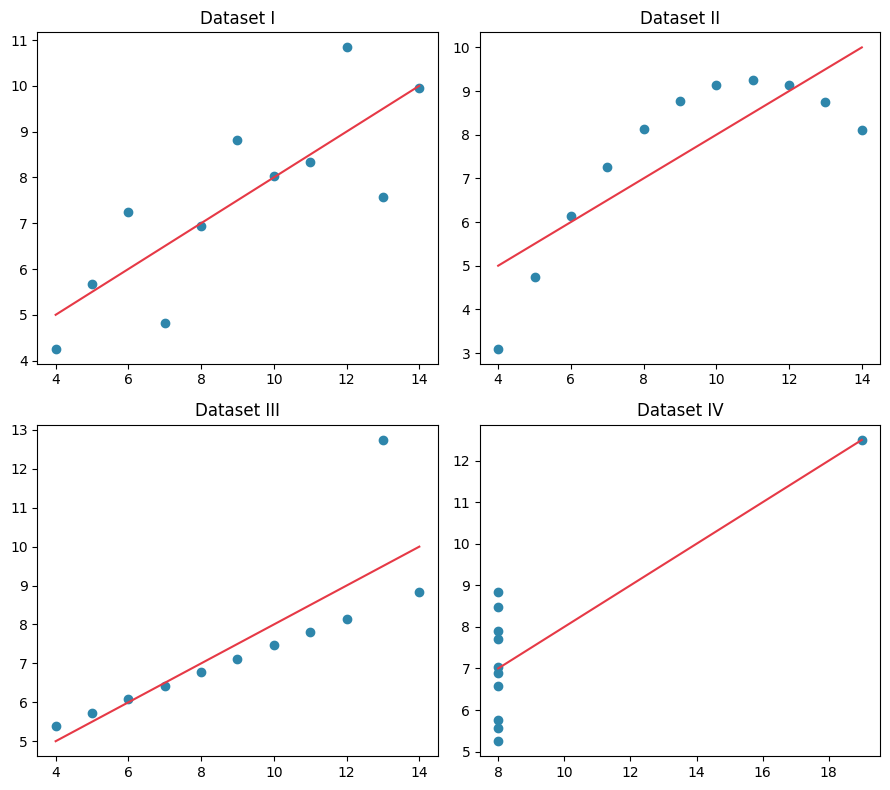


All four tables of numbers are nearly identical -- but the plots tell four
completely different stories: I is a genuine linear relationship, II is a
clean CURVE that Pearson r mislabels as 'linear', III is a perfect line
wrecked by one outlier, and IV is a vertical cluster entirely driven by a
single high-leverage point. Trusting the numbers alone would have concluded
all four are 'the same' relationship.
네 개의 숫자 표는 거의 동일하지만, 그래프는 완전히 다른 네 가지 이야기를
들려줍니다: I는 진짜 선형 관계, II는 Pearson r이 '선형'이라고 잘못 표시하는
깔끔한 곡선, III은 이상치 하나가 망친 완벽한 직선, IV는 레버리지가 큰 점
하나가 전체를 좌우하는 수직 군집입니다. 숫자만 믿었다면 네 관계가 모두
'동일하다'고 결론 내렸을 것입니다.


In [7]:
# Business question: a colleague reports "mean(x)=9.0, mean(y)=7.5, var(x)=11.0,
# var(y)=4.1, r=0.816" for four different (x, y) pairs. Are these four
# relationships the same? Only a plot can tell you.
# 비즈니스 질문: 동료가 네 개의 서로 다른 (x, y) 쌍에 대해 "mean(x)=9.0,
# mean(y)=7.5, var(x)=11.0, var(y)=4.1, r=0.816"이라고 보고합니다.
# 이 네 관계가 정말 같을까요? 오직 그래프만이 답해줄 수 있습니다.

import matplotlib.pyplot as plt

x = [10, 8, 13, 9, 11, 14, 6, 4, 12, 7, 5]
y1 = [8.04, 6.95, 7.58, 8.81, 8.33, 9.96, 7.24, 4.26, 10.84, 4.82, 5.68]
y2 = [9.14, 8.14, 8.74, 8.77, 9.26, 8.10, 6.13, 3.10, 9.13, 7.26, 4.74]
y3 = [7.46, 6.77, 12.74, 7.11, 7.81, 8.84, 6.08, 5.39, 8.15, 6.42, 5.73]
x4 = [8, 8, 8, 8, 8, 8, 8, 19, 8, 8, 8]
y4 = [6.58, 5.76, 7.71, 8.84, 8.47, 7.04, 5.25, 12.50, 5.56, 7.91, 6.89]

datasets = {
    'I': pd.DataFrame({'x': x, 'y': y1}),
    'II': pd.DataFrame({'x': x, 'y': y2}),
    'III': pd.DataFrame({'x': x, 'y': y3}),
    'IV': pd.DataFrame({'x': x4, 'y': y4}),
}

print(f"{'Dataset':<8}{'mean(x)':>9}{'mean(y)':>9}{'var(x)':>9}{'var(y)':>9}{'r':>9}")
for name, d in datasets.items():
    r, _ = stats.pearsonr(d['x'], d['y'])
    print(f"{name:<8}{d['x'].mean():>9.2f}{d['y'].mean():>9.2f}{d['x'].var():>9.2f}{d['y'].var():>9.2f}{r:>9.3f}")

fig, axes = plt.subplots(2, 2, figsize=(9, 8))
for ax, (name, d) in zip(axes.flat, datasets.items()):
    ax.scatter(d['x'], d['y'], color='#2E86AB')
    m, b = np.polyfit(d['x'], d['y'], 1)
    x_line = np.linspace(d['x'].min(), d['x'].max(), 50)
    ax.plot(x_line, m * x_line + b, color='#E63946', linewidth=1.5)
    ax.set_title(f"Dataset {name}")
plt.tight_layout()
plt.show()

print()
print("All four tables of numbers are nearly identical -- but the plots tell four")
print("completely different stories: I is a genuine linear relationship, II is a")
print("clean CURVE that Pearson r mislabels as 'linear', III is a perfect line")
print("wrecked by one outlier, and IV is a vertical cluster entirely driven by a")
print("single high-leverage point. Trusting the numbers alone would have concluded")
print("all four are 'the same' relationship.")
print("네 개의 숫자 표는 거의 동일하지만, 그래프는 완전히 다른 네 가지 이야기를")
print("들려줍니다: I는 진짜 선형 관계, II는 Pearson r이 '선형'이라고 잘못 표시하는")
print("깔끔한 곡선, III은 이상치 하나가 망친 완벽한 직선, IV는 레버리지가 큰 점")
print("하나가 전체를 좌우하는 수직 군집입니다. 숫자만 믿었다면 네 관계가 모두")
print("'동일하다'고 결론 내렸을 것입니다.")

## Example 6 — Practice: Apply All Four Concepts (연습: 네 가지 개념 모두 적용하기)

Fill in every `________` blank below. The cell runs with **no errors** even if you leave blanks — it just prints a reminder instead of that part's result.

아래 `________` 빈칸을 모두 채워보세요. 빈칸을 두어도 셀은 **에러 없이** 실행되며, 그 부분의 결과 대신 안내 메시지만 출력됩니다.

In [10]:
# ============================================================
# Practice -- fill in every ________ blank, then re-run the cell
# 연습 -- 아래 ________ 빈칸을 모두 채운 뒤 셀을 다시 실행하세요
# ============================================================
BLANK = "________"

def ready(*vals):
    return all(v != BLANK for v in vals)

# ---------- Part A: covariance -- discount % and units sold ----------
np.random.seed(5)
discount_pct = np.random.uniform(0, 40, 100)
units_sold = discount_pct * 3 + np.random.normal(0, 15, 100)
df_a = pd.DataFrame({'discount_pct': discount_pct, 'units_sold': units_sold})

cov_method_a = 'cov'   # TODO: which pandas Series method computes covariance? ('cov')

if ready(cov_method_a):
    cov_val = getattr(df_a['discount_pct'], cov_method_a)(df_a['units_sold'])
    print(f"Covariance: {cov_val:.2f}")
else:
    print("Part A \u270f\ufe0f  Fill in cov_method_a above, then re-run.")

# ---------- Part B: Pearson -- ad impressions and clicks ----------
np.random.seed(6)
impressions = np.random.uniform(1000, 10000, 150)
clicks = impressions * 0.03 + np.random.normal(0, 50, 150)
df_b = pd.DataFrame({'impressions': impressions, 'clicks': clicks})

corr_func_b = 'pearsonr'   # TODO: which scipy.stats function returns (r, p-value) for Pearson? ('pearsonr')

if ready(corr_func_b):
    r_val, p_val = getattr(stats, corr_func_b)(df_b['impressions'], df_b['clicks'])
    print(f"r = {r_val:.3f}, r-squared = {r_val ** 2:.3f}, p = {p_val:.2e}")
else:
    print("Part B \u270f\ufe0f  Fill in corr_func_b above, then re-run.")

# ---------- Part C: Spearman -- rank-based check on a diminishing-returns curve ----------
np.random.seed(7)
experience_years = np.random.uniform(0, 15, 100)
salary_level = np.sqrt(experience_years) * 20 + np.random.normal(0, 3, 100)
df_c = pd.DataFrame({'experience_years': experience_years, 'salary_level': salary_level})

method_c = 'spearman'   # TODO: 'pearson' or 'spearman' -- which handles a curved-but-monotonic
                   # relationship better?

if ready(method_c):
    corr_val = df_c['experience_years'].corr(df_c['salary_level'], method=method_c)
    print(f"{method_c} correlation: {corr_val:.3f}")
else:
    print("Part C \u270f\ufe0f  Fill in method_c above, then re-run.")

# ---------- Part D: confounder check -- season, ad spend, and sales ----------
np.random.seed(8)
n = 200
is_summer_d = np.random.choice([True, False], n)
ad_spend_d = 500 + np.where(is_summer_d, 300, 0) + np.random.normal(0, 50, n)
sales_d = 2000 + np.where(is_summer_d, 1500, 0) + np.random.normal(0, 200, n)
df_d = pd.DataFrame({'ad_spend': ad_spend_d, 'sales': sales_d, 'is_summer': is_summer_d})

group_d = False   # TODO: True or False -- pick one season group to check the WITHIN-group correlation for

if ready(group_d):
    sub_d = df_d[df_d['is_summer'] == group_d]
    within_corr_d = sub_d['ad_spend'].corr(sub_d['sales'])
    overall_corr_d = df_d['ad_spend'].corr(df_d['sales'])
    print(f"Overall correlation: {overall_corr_d:.3f}")
    print(f"Within is_summer={group_d} correlation: {within_corr_d:.3f}")
else:
    print("Part D \u270f\ufe0f  Fill in group_d above (True or False), then re-run.")

Covariance: 438.25
r = 0.855, r-squared = 0.730, p = 5.87e-44
spearman correlation: 0.981
Overall correlation: 0.912
Within is_summer=False correlation: -0.050


---
# ⚠️ Common Mistakes (자주 하는 실수)

### Mistake 1 — Treating Covariance as Directly Comparable Across Variable Pairs (공분산을 변수 쌍 간 직접 비교 가능하다고 취급)
A covariance of 5,000 between two dollar-denominated variables and a covariance of 5,000 between two small-scale variables (like a 1-5 rating) represent completely different relationship strengths — covariance's scale depends entirely on the units of the variables involved.  
달러 단위 변수 두 개 사이의 공분산 5,000과 작은 척도(1-5 평점 등) 변수 두 개 사이의 공분산 5,000은 완전히 다른 관계 강도를 나타냅니다 -- 공분산의 크기는 전적으로 관련 변수의 단위에 좌우됩니다.

✅ **Fix / 해결:** Use correlation (standardized to -1 to 1) whenever you need to compare relationship strength across different variable pairs; reserve covariance for intermediate math steps.

### Mistake 2 — Using Pearson on a Curved-but-Consistent Relationship (곡선이지만 일관된 관계에 Pearson 사용)
Pearson correlation specifically measures LINEAR fit — a relationship that consistently rises but curves (like diminishing returns) gets an artificially LOW Pearson score even though the two variables move together very reliably.  
Pearson 상관계수는 특히 선형 적합을 측정합니다 -- 일관되게 상승하지만 곡선인 관계(수확체감 등)는 두 변수가 매우 안정적으로 함께 움직임에도 불구하고 인위적으로 낮은 Pearson 점수를 받습니다.

✅ **Fix / 해결:** If a scatter plot shows a clear but curved pattern, compute Spearman alongside Pearson — a much higher Spearman value confirms a real, monotonic (if non-linear) relationship.

### Mistake 3 — Treating Correlation as Proof of Causation (상관관계를 인과관계의 증거로 취급)
A strong correlation between ad spend and revenue could mean ads drive sales — or it could mean a third factor (like holiday seasonality) drives both, exactly as Example 4 demonstrates. Correlation alone can never distinguish between these explanations.  
광고비와 매출 사이의 강한 상관관계는 광고가 매출을 이끈다는 의미일 수도 있지만, 예제 4가 보여주듯 제3의 요인(휴일 시즌성 등)이 둘 다를 이끈다는 의미일 수도 있습니다. 상관관계만으로는 이 설명들을 절대 구분할 수 없습니다.

✅ **Fix / 해결:** Before claiming causation, check for plausible confounders, look at the relationship within subgroups (as in Example 4), or — ideally — run a controlled A/B test.

### Mistake 4 — Assuming a Correlation Near Zero Means "No Relationship" (0에 가까운 상관계수를 "관계 없음"으로 착각)
Both Pearson and Spearman are built to catch relationships that move consistently in one direction — a U-shaped or perfectly cyclical relationship (where the variable goes up, then down) can produce a correlation near 0 despite a very real, strong pattern.  
Pearson과 Spearman 둘 다 한 방향으로 일관되게 움직이는 관계를 포착하도록 설계되었습니다 -- U자형이나 완전히 주기적인 관계(변수가 오르다가 다시 내려가는)는 매우 실재하고 강한 패턴이 있어도 0에 가까운 상관계수가 나올 수 있습니다.

✅ **Fix / 해결:** Always plot a scatter plot before concluding "no relationship" from a low correlation number alone — the shape can reveal a real pattern that the single number hides.

### Mistake 5 — Letting One Extreme Outlier Dominate a Pearson Correlation (하나의 극단적 이상치가 Pearson 상관계수를 지배하게 둠)
Because Pearson correlation is built from raw values (not ranks), a single extreme data-entry error or genuine outlier can swing the correlation dramatically, sometimes flipping its sign entirely.  
Pearson 상관계수는 순위가 아니라 원본 값으로 만들어지기 때문에, 하나의 극단적인 데이터 입력 오류나 진짜 이상치가 상관계수를 크게 흔들 수 있으며, 때로는 부호 자체를 뒤집기도 합니다.

✅ **Fix / 해결:** Check the same relationship with Spearman (far less sensitive to outliers, since it uses ranks) — a big gap between Pearson and Spearman is a red flag worth investigating.

### Mistake 6 — Confusing Statistical Strength with Business Importance (통계적 강도와 비즈니스 중요성 혼동)
"Revenue correlates with units sold at r=0.98" is statistically huge but businesswise trivial (of course they move together) — meanwhile, "customer satisfaction correlates with retention at r=0.25" might be statistically modest but represents a genuinely actionable lever in a noisy business environment.  
"매출은 판매 개수와 r=0.98로 상관된다"는 통계적으로는 매우 크지만 비즈니스적으로는 당연한 이야기입니다(당연히 함께 움직임) -- 반면 "고객 만족도는 리텐션과 r=0.25로 상관된다"는 통계적으로는 보통이지만 노이즈가 많은 비즈니스 환경에서 진짜 실행 가능한 레버를 나타낼 수 있습니다.

✅ **Fix / 해결:** Always interpret a correlation's size in the context of what's realistically achievable and actionable in your specific domain, not against a universal "strong/weak" scale.

### Mistake 7 — Trusting Any Summary Statistic Without Ever Plotting the Data (그래프 없이 요약 통계만 신뢰)
As Anscombe's Quartet (Example 5) shows, four datasets can share an identical mean, variance, and correlation coefficient while looking nothing alike — a genuine line, a curve, a line wrecked by one outlier, and a cluster driven by a single point. No combination of summary numbers alone can rule any of these out.  
Anscombe's Quartet(예제 5)가 보여주듯, 네 개의 데이터셋이 평균·분산·상관계수까지 완전히 동일하면서도 실제로는 전혀 다르게 생길 수 있습니다 — 진짜 직선, 곡선, 이상치 하나에 망가진 직선, 점 하나가 좌우하는 군집. 요약 숫자를 아무리 조합해도 이 중 어떤 것도 배제할 수 없습니다.

✅ **Fix / 해결:** Before reporting any correlation (or any statistic from earlier sections), plot a scatter plot first — treat the number as a caption for the picture, never as a replacement for it.  
✅ **해결:** 어떤 상관계수(또는 이전 섹션의 어떤 통계값)든 보고하기 전에 먼저 산점도를 그리세요 — 숫자는 그림을 대체하는 것이 아니라 그림의 설명(caption)일 뿐입니다.

---
# 💡 Tips (팁)
Useful tips or shortcuts / 유용한 팁과 단축법

- pandas' `.corr()` defaults to Pearson but accepts `method='spearman'` or `method='kendall'` as a one-word switch — compute both Pearson and Spearman by default as a quick linearity sanity check.<br>pandas의 .corr()은 기본적으로 Pearson을 사용하지만 method='spearman'이나 method='kendall'로 한 단어만 바꾸면 전환됩니다 -- 기본적으로 Pearson과 Spearman을 둘 다 계산해 선형성을 빠르게 점검하세요.
- `df.corr()` on a whole DataFrame gives you a full correlation matrix in one call — pair it with a Seaborn heatmap to scan for relationships across many variables at once.<br>DataFrame 전체에 df.corr()을 쓰면 전체 상관관계 행렬을 한 번에 얻습니다 -- Seaborn 히트맵과 짝지으면 여러 변수 간 관계를 한 번에 훑어볼 수 있습니다.
- The classic "ice cream sales correlate with drowning deaths" example exists precisely to make Mistake 3 memorable — the real driver behind both is hot weather, not ice cream causing drowning.<br>"아이스크림 판매량이 익사 사고와 상관된다"는 고전적인 예시는 정확히 실수 3을 기억에 남게 하려고 존재합니다 -- 둘 다의 진짜 원인은 더운 날씨이지, 아이스크림이 익사를 유발하는 게 아닙니다.
- r-squared (correlation squared) has a clean interpretation Pearson's r alone doesn't: "the percentage of variation in Y explained by X" — useful phrasing for a business audience.<br>결정계수(상관계수의 제곱)는 Pearson의 r 자체에는 없는 깔끔한 해석을 제공합니다: "X가 설명하는 Y 변동의 비율" -- 비즈니스 청중에게 유용한 표현입니다.
- The Regression sections ahead build directly on correlation — a strong Pearson r is usually your first sign that a simple linear regression model is worth trying.<br>이후 회귀 섹션은 상관관계 위에 직접 세워집니다 -- 강한 Pearson r은 보통 단순 선형회귀 모델을 시도해볼 만하다는 첫 신호입니다.
- Keep Anscombe's Quartet in your back pocket as the go-to example whenever someone asks "why bother plotting if I already have the numbers?" — it's the single most convincing 30-second demo of that point.<br>"숫자가 이미 있는데 왜 그래프까지 그려야 하나요?"라는 질문을 받을 때를 대비해 Anscombe's Quartet을 기억해두세요 -- 이 질문에 대한 가장 설득력 있는 30초짜리 시연입니다.

---
# 🔗 Related Concepts (관련 개념)

```
[ Part 1: Foundational Statistics complete / Part 1: 기초 통계 완료 ]
Descriptive Statistics -> Probability Fundamentals -> Probability Distributions
   -> Sampling & Confidence Intervals -> Correlation & Covariance (Section 5, here)
        ↓
[ Part 2: Hypothesis Testing begins / Part 2: 가설 검정 시작 ]
Hypothesis Testing Fundamentals (Section 6)
   p-values, significance, Type I/II errors
        ↓
t-Tests -> Chi-Square -> ANOVA -> Non-Parametric Tests
        ↓
[ Part 3: Regression / Part 3: 회귀분석 ] -> [ Part 4: A/B Testing in Practice ]
```

*How is today's topic connected to other concepts?*

**EN:** This section closes out Part 1 (Foundational Statistics) — everything from here forward in Part 2 is about formally TESTING whether a pattern you notice (like a correlation) is real or just noise. In fact, the correlation coefficient you compute here is directly tested for statistical significance using a hypothesis test in Section 6 (the p-value scipy handed back alongside `r` is exactly that test). And the "correlation isn't causation" caution from Example 4 becomes even more important once you reach Regression in Part 3 — a regression coefficient has the exact same confounder vulnerability as a correlation does. Anscombe's Quartet (Example 5) also loops all the way back to Section 1 — the same "never trust a summary number without plotting" lesson that applied to mean/median/skewness applies just as much to a correlation coefficient.

**KR:** 이 섹션으로 Part 1(기초 통계)이 마무리됩니다 -- 여기서부터 Part 2는 눈에 띈 패턴(상관관계 등)이 실제인지 그냥 노이즈인지를 공식적으로 검정하는 것에 관한 내용입니다. 실제로 여기서 계산한 상관계수는 섹션 6의 가설검정을 사용해 통계적 유의성이 직접 검정됩니다(scipy가 r과 함께 돌려준 p-value가 정확히 그 검정입니다). 그리고 예제 4의 "상관관계는 인과관계가 아니다"라는 경고는 Part 3의 회귀분석에 이르면 훨씬 더 중요해집니다 -- 회귀계수는 상관계수와 정확히 같은 교란변수 취약점을 가집니다. Anscombe's Quartet(예제 5)은 섹션 1까지 거슬러 연결되기도 합니다 -- 평균/중앙값/왜도에 적용됐던 "요약 숫자만 믿지 말고 반드시 그래프를 그려라"는 교훈이 상관계수에도 똑같이 적용됩니다.

---
# 💼 Business Example (비즈니스 예시)
*How would a Business Analyst use this?*

**Scenario / 시나리오:**

**EN:** Your product team notices that customers with slower support response times have higher churn rates, and correlation confirms it: r = 0.6. Before recommending a costly investment in faster support staffing, leadership wants to know: could a THIRD factor (like customer plan tier) be driving both slow support AND churn?

**KR:** 제품팀이 지원 응답 시간이 느린 고객일수록 이탈률이 높다는 것을 발견했고, 상관관계도 이를 확인해줍니다: r = 0.6. 더 빠른 지원 인력에 대한 비용이 큰 투자를 권고하기 전에, 경영진은 제3의 요인(고객 플랜 등급 등)이 느린 지원과 이탈을 둘 다 이끌고 있는 것은 아닌지 알고 싶어합니다.

**To-do / 할 일:**
- [x] Compute the overall correlation between response time and churn<br>응답시간과 이탈 사이의 전체 상관관계 계산하기
- [x] Check whether plan tier (free vs paid) could be a confounder by comparing within-group correlations<br>그룹 내 상관관계를 비교해 플랜 등급(무료 vs 유료)이 교란변수인지 확인하기
- [x] Decide whether the relationship holds up within each tier, or mostly disappears<br>각 등급 내에서 관계가 유지되는지, 아니면 대부분 사라지는지 판단하기
- [x] Write a recommendation about the support staffing investment<br>지원 인력 투자에 관한 제안 작성하기

In [9]:
np.random.seed(9)
n = 300
plan_tier = np.random.choice(['Free', 'Paid'], n, p=[0.6, 0.4])
# Free tier gets slower support AND churns more, regardless of any direct causal link
response_time = np.where(plan_tier == 'Free', 45, 12) + np.random.normal(0, 8, n)
churn = np.where(plan_tier == 'Free', 0.35, 0.08) + np.random.normal(0, 0.05, n)
df_churn = pd.DataFrame({'plan_tier': plan_tier, 'response_time_min': response_time, 'churn_rate': churn})

overall_r = df_churn['response_time_min'].corr(df_churn['churn_rate'])
print(f"Overall correlation (response time vs churn): {overall_r:.3f}")
print()

for tier, sub in df_churn.groupby('plan_tier'):
    within_r = sub['response_time_min'].corr(sub['churn_rate'])
    print(f"{tier} tier only: correlation = {within_r:.3f} (n={len(sub)})")

print()
print("The overall correlation looks strong, but within each plan tier separately, the")
print("relationship nearly disappears -- plan tier is a confounder driving both slower")
print("support (free tier gets less priority) and higher churn (free users churn more")
print("regardless of support speed). Recommendation: investigate WHY free tier churns")
print("before assuming faster support alone will fix it.")

print()
print(f"전체 상관관계(응답시간 vs 이탈): {overall_r:.3f}")
for tier, sub in df_churn.groupby('plan_tier'):
    within_r = sub['response_time_min'].corr(sub['churn_rate'])
    tier_kr = '무료' if tier == 'Free' else '유료'
    print(f"{tier_kr} 등급만: 상관관계 = {within_r:.3f} (n={len(sub)})")
print("전체 상관관계는 강해 보이지만, 각 플랜 등급 내에서는 관계가 거의 사라집니다 --")
print("플랜 등급이 느린 지원(무료 등급이 우선순위가 낮음)과 높은 이탈(무료 사용자는")
print("지원 속도와 무관하게 더 많이 이탈) 둘 다를 이끄는 교란변수입니다. 제안: 빠른")
print("지원만으로 해결될 것이라 가정하기 전에 무료 등급이 왜 이탈하는지 조사가 필요합니다.")

Overall correlation (response time vs churn): 0.818

Free tier only: correlation = -0.147 (n=182)
Paid tier only: correlation = -0.009 (n=118)

The overall correlation looks strong, but within each plan tier separately, the
relationship nearly disappears -- plan tier is a confounder driving both slower
support (free tier gets less priority) and higher churn (free users churn more
regardless of support speed). Recommendation: investigate WHY free tier churns
before assuming faster support alone will fix it.

전체 상관관계(응답시간 vs 이탈): 0.818
무료 등급만: 상관관계 = -0.147 (n=182)
유료 등급만: 상관관계 = -0.009 (n=118)
전체 상관관계는 강해 보이지만, 각 플랜 등급 내에서는 관계가 거의 사라집니다 --
플랜 등급이 느린 지원(무료 등급이 우선순위가 낮음)과 높은 이탈(무료 사용자는
지원 속도와 무관하게 더 많이 이탈) 둘 다를 이끄는 교란변수입니다. 제안: 빠른
지원만으로 해결될 것이라 가정하기 전에 무료 등급이 왜 이탈하는지 조사가 필요합니다.


---
# 📝 Summary (요약)
*Write today's concept in 3~5 sentences.*

**EN:** Covariance captures the direction two variables move together, but its scale depends on the variables' units, making raw covariance values impossible to compare across different variable pairs. Correlation solves this by standardizing to a unitless -1 to 1 scale: Pearson correlation measures specifically linear relationships and is sensitive to outliers (since it uses raw values), while Spearman correlation measures monotonic relationships more broadly (any consistent direction, even curved) and resists outliers by working with ranks instead. The single most important caution in this section — reinforced by Example 4's simulation — is that even a very strong correlation never proves causation on its own: a hidden confounder (like seasonality driving both ad spend and revenue, or plan tier driving both support speed and churn) can produce a strong overall correlation that mostly vanishes once you control for the real driver. Anscombe's Quartet (Example 5) delivers a second, equally important caution: four datasets with identical mean, variance, and correlation can have completely different shapes, so no correlation number should ever be reported without a scatter plot beside it.

**KR:** 공분산은 두 변수가 함께 움직이는 방향을 포착하지만, 그 크기는 변수의 단위에 좌우되어 서로 다른 변수 쌍 사이의 원본 공분산 값을 비교할 수 없게 만듭니다. 상관계수는 단위 없는 -1에서 1 척도로 표준화해 이를 해결합니다: Pearson 상관계수는 특히 선형 관계를 측정하며 원본 값을 사용하기 때문에 이상치에 민감하고, Spearman 상관계수는 순위를 사용해 더 넓은 범위의 단조 관계(곡선이라도 일관된 방향)를 측정하며 이상치에 강합니다. 이 섹션에서 가장 중요한 경고 — 예제 4의 시뮬레이션으로 강조됨 — 는 아무리 강한 상관관계라도 그 자체로는 절대 인과관계를 증명하지 않는다는 것입니다: 숨은 교란변수(시즌성이 광고비와 매출 둘 다를 이끄는 경우, 플랜 등급이 지원 속도와 이탈 둘 다를 이끄는 경우)가 실제 원인을 통제하면 대부분 사라지는 강한 전체 상관관계를 만들어낼 수 있습니다. Anscombe's Quartet(예제 5)는 이에 못지않게 중요한 두 번째 경고를 줍니다: 평균·분산·상관계수가 동일한 네 데이터셋이 완전히 다른 모양일 수 있으므로, 상관계수는 언제나 산점도와 함께 보고해야 합니다.

---
# 📌 One Sentence Summary (한 문장 요약)
Today's topic in ONE sentence. / 오늘의 주제를 한 문장으로.

> **EN:** Correlation standardizes covariance into a comparable -1 to 1 number (Pearson for linear relationships, Spearman for monotonic ones), but no matter how strong that number is, it never proves causation on its own — a hidden confounder can make two unrelated variables look tightly linked.

> **KR:** 상관계수는 공분산을 비교 가능한 -1에서 1 사이의 숫자로 표준화하지만(선형 관계는 Pearson, 단조 관계는 Spearman), 그 숫자가 아무리 강해도 그 자체로는 절대 인과관계를 증명하지 않습니다 -- 숨은 교란변수가 서로 관계없는 두 변수를 밀접하게 연결된 것처럼 보이게 만들 수 있습니다.

---
# ❓ Review Questions (복습 질문)

**Q1 (EN).** Why can't you compare a covariance of 5,000 between two dollar variables to a covariance of 5,000 between two 1-5 rating variables?  
**Q1 (KR).** 두 달러 변수 사이의 공분산 5,000을 두 1-5 평점 변수 사이의 공분산 5,000과 왜 비교할 수 없나요?

A covariance of 5,000 still carries the units of both variables, so the two 5,000s are not the same size of relationship.  
달러×달러와 평점×평점은 단위가 달라서, 공분산 숫자 5,000끼리는 비교할 수 없습니다.

**Q2 (EN).** A scatter plot shows a clear, consistently rising curve (not a straight line). Why might Spearman correlation be higher than Pearson correlation here?  
**Q2 (KR).** 산점도가 명확하고 일관되게 상승하는 곡선(직선이 아님)을 보여줍니다. 여기서 Spearman 상관계수가 Pearson 상관계수보다 왜 더 높을 수 있나요?

Spearman only checks whether the ranks keep rising together, so a curve that always goes up still scores high. Pearson only rewards a straight line, so it comes out lower.  
순위가 계속 같이 올라가면 Spearman은 높습니다. Pearson은 직선만 높게 봐서, 곡선이면 더 낮게 나옵니다.

**Q3 (EN).** Ice cream sales correlate strongly with drowning deaths. What's the real explanation, and what statistical concept does this illustrate?  
**Q3 (KR).** 아이스크림 판매량은 익사 사고와 강하게 상관됩니다. 실제 설명은 무엇이며, 이는 어떤 통계 개념을 보여주나요?

Hot weather drives both ice cream sales and drowning. The correlation is real, but ice cream does not cause drowning.  
더운 날씨가 둘 다를 올립니다. 같이 움직이지만 원인은 아이스크림이 아닙니다. 숨은 교란변수입니다.

**Q4 (EN).** You find a correlation of 0.02 between two variables and conclude "no relationship." What could you be missing?  
**Q4 (KR).** 두 변수 사이의 상관계수가 0.02로 나와 "관계 없음"이라고 결론 내렸습니다. 무엇을 놓치고 있을 수 있나요?

A correlation near 0 can hide a U-shape: the variable goes up, then down, so the one-direction score cancels out.  
한쪽 방향으로만 보는 점수라서, 올랐다가 내려가는 관계는 0 근처가 될 수 있습니다. 산점도를 봐야 합니다.

**Q5 (EN).** How does checking a correlation WITHIN subgroups (like Example 4's holiday vs regular months) help you tell a real relationship apart from a confounded one?  
**Q5 (KR).** 하위 그룹 내에서(예제 4의 휴일 vs 평상시처럼) 상관관계를 확인하는 것이 실제 관계와 교란된 관계를 구분하는 데 어떻게 도움이 되나요?

Compute the correlation again inside each subgroup. If it disappears, a third factor was moving both variables together.  
휴일만, 평상시만 따로 보면 상관이 거의 사라집니다. 전체에서 강해 보인 것은 시즌이 광고비와 매출을 같이 올렸기 때문입니다.

**Q6 (EN).** All four datasets in Anscombe's Quartet share the same mean, variance, and Pearson r ≈ 0.816. Name at least two ways their scatter plots actually differ, and explain what general lesson this teaches about summary statistics.  
**Q6 (KR).** Anscombe's Quartet의 네 데이터셋은 모두 같은 평균, 분산, Pearson r ≈ 0.816을 가집니다. 실제 산점도가 다른 점을 최소 두 가지 말하고, 이것이 요약 통계에 대해 어떤 일반적인 교훈을 주는지 설명하세요.

One plot is a straight line, another is a curve, another is a line pulled by one outlier, and the last is a cluster driven by a single point.  
같은 평균·분산·r이라도 산점도는 직선, 곡선, 이상치에 꺾인 직선, 점 하나가 만든 수직 덩어리로 다릅니다. 요약 숫자는 모양을 알려 주지 않습니다.

---
*📅 Try answering these again in a few days. / 며칠 후 다시 답해보세요.*
*🎉 This completes Part 1: Foundational Statistics. Part 2: Hypothesis Testing starts next. / 이것으로 Part 1: 기초 통계가 완료되었습니다. 다음은 Part 2: 가설 검정입니다.*